# H4-1 nonparametric hypothesis tests: Wilcoxon / Mann-Whitney U

**Premises (settled in the earlier notebooks)**
- Stable window: WEEK_NO 17-99, with 10 weeks each for the early and late windows
- Top 20% households: fixed on early-window spending
- Normality and equal variances were both rejected, so nonparametric tests are used
- Sensitivity check results (N=8, 10, 12): the "convergence pattern", in which top-spending households spend less in the late window and the rest spend more, appears consistently regardless of N. We judge it a real pattern and run the main tests with N=10

**Three tests (Bonferroni correction, alpha = 0.05/3 = about 0.0167)**
- A. Is the change in absolute spending of the top 20% households significant (Wilcoxon signed-rank test, paired)
- B. Is the change in absolute spending of the remaining 80% households significant (Wilcoxon signed-rank test, paired); the comparison control
- C. Do the increases (diff) of the two groups differ from each other (Mann-Whitney U, independent)

Every test reports **p-value + effect size + 95% confidence interval** together.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)
from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

tx = pd.read_csv(DATA_DIR / "transaction_data.csv")

STABLE_MIN_WEEK = 17
STABLE_MAX_WEEK = 99
EARLY_N = 10
TOP_X_PCT = 20
N_BOOT = 5000  # number of bootstrap repetitions

tx_stable = tx[(tx["WEEK_NO"] >= STABLE_MIN_WEEK) & (tx["WEEK_NO"] <= STABLE_MAX_WEEK)].copy()


## 1. Prepare the data (same definitions as the previous notebooks)

In [2]:
early_window = tx_stable[
    (tx_stable["WEEK_NO"] >= STABLE_MIN_WEEK) &
    (tx_stable["WEEK_NO"] < STABLE_MIN_WEEK + EARLY_N)
]
late_window = tx_stable[
    (tx_stable["WEEK_NO"] > STABLE_MAX_WEEK - EARLY_N) &
    (tx_stable["WEEK_NO"] <= STABLE_MAX_WEEK)
]

sales_early = early_window.groupby("household_key")["SALES_VALUE"].sum().rename("sales_early")
sales_late  = late_window.groupby("household_key")["SALES_VALUE"].sum().rename("sales_late")

panel = pd.concat([sales_early, sales_late], axis=1).dropna()
panel["diff"] = panel["sales_late"] - panel["sales_early"]

cutoff_value = panel["sales_early"].quantile(1 - TOP_X_PCT/100)
panel["group"] = np.where(panel["sales_early"] >= cutoff_value, "top 20%", "remaining 80%")

top_diff  = panel.loc[panel["group"] == "top 20%", "diff"].values
rest_diff = panel.loc[panel["group"] == "remaining 80%", "diff"].values

print(f"Top 20%: n={len(top_diff)}, mean diff={top_diff.mean():.2f}, median diff={np.median(top_diff):.2f}")
print(f"Remaining 80%: n={len(rest_diff)}, mean diff={rest_diff.mean():.2f}, median diff={np.median(rest_diff):.2f}")

N_TESTS = 3
ALPHA = 0.05
ALPHA_ADJ = ALPHA / N_TESTS
print(f"\nBonferroni-corrected significance level: {ALPHA_ADJ:.4f} (original {ALPHA} / {N_TESTS} tests)")


Top 20%: n=419, mean diff=-111.49, median diff=-131.45
Remaining 80%: n=1676, mean diff=102.74, median diff=36.49

Bonferroni-corrected significance level: 0.0167 (original 0.05 / 3 tests)


In [3]:
# --- source CSVs: household-level panel (intermediate), group summary and boxplot statistics
from matplotlib.cbook import boxplot_stats
panel.to_csv(INTERMEDIATE_DIR / "h4_panel_households.csv", index_label="household_key")
pd.DataFrame([
    {"group": "top20", "n": len(top_diff), "mean_diff": top_diff.mean(), "median_diff": np.median(top_diff)},
    {"group": "rest80", "n": len(rest_diff), "mean_diff": rest_diff.mean(), "median_diff": np.median(rest_diff)},
]).to_csv(OUT_DIR / "h4_group_diff_summary.csv", index=False)
_bx, _fl = [], []
for _g, _arr in [("top20", top_diff), ("rest80", rest_diff)]:
    _st = boxplot_stats(_arr)[0]
    _bx.append({"group": _g, "n": len(_arr), **{k: _st[k] for k in ["q1", "med", "q3", "whislo", "whishi", "mean"]}})
    _fl += [{"group": _g, "value": v} for v in sorted(_st["fliers"])]
pd.DataFrame(_bx).to_csv(OUT_DIR / "h4_diff_boxplot_stats.csv", index=False)
pd.DataFrame(_fl).to_csv(OUT_DIR / "h4_diff_boxplot_fliers.csv", index=False)

## 2. Helper functions for effect sizes and confidence intervals

- Effect size of the Wilcoxon signed-rank test: rank-biserial correlation (r = Z / sqrt(N))
- Effect size of the Mann-Whitney U: rank-biserial correlation + common language effect size
- All confidence intervals are computed by **bootstrap** (on the median difference, 5000 resamples), consistent with the nonparametric tests

In [4]:
def bootstrap_ci_median(x, rng, n_boot=N_BOOT, ci=95):
    """Bootstrap confidence interval of a single-sample median"""
    boot_medians = np.array([
        np.median(rng.choice(x, size=len(x), replace=True))
        for _ in range(n_boot)
    ])
    lo, hi = np.percentile(boot_medians, [(100-ci)/2, 100-(100-ci)/2])
    return lo, hi

def bootstrap_ci_median_diff(x, y, rng, n_boot=N_BOOT, ci=95):
    """Bootstrap confidence interval of the median difference between two independent samples (median(x) - median(y))"""
    boot_diffs = np.empty(n_boot)
    for i in range(n_boot):
        bx = rng.choice(x, size=len(x), replace=True)
        by = rng.choice(y, size=len(y), replace=True)
        boot_diffs[i] = np.median(bx) - np.median(by)
    lo, hi = np.percentile(boot_diffs, [(100-ci)/2, 100-(100-ci)/2])
    return lo, hi

def wilcoxon_effect_size(x):
    """Rank-biserial correlation of the Wilcoxon signed-rank test (z-approximation based)"""
    res = stats.wilcoxon(x, alternative='two-sided', zero_method='wilcox', method='approx')
    n = len(x)
    r = res.zstatistic / np.sqrt(n)
    return res.statistic, res.pvalue, r

def mannwhitney_effect_size(x, y):
    """Rank-biserial correlation of the Mann-Whitney U + common language effect size"""
    u_stat, p = stats.mannwhitneyu(x, y, alternative='two-sided')
    n1, n2 = len(x), len(y)
    rank_biserial = 1 - (2*u_stat) / (n1*n2)
    common_language = u_stat / (n1*n2)
    return u_stat, p, rank_biserial, common_language


## 3. Test A: top 20% households, change in absolute spending (Wilcoxon signed-rank test)

Null hypothesis: the median of the early-to-late spending difference (diff) of the top 20% households is 0 (no change)

In [5]:
stat_A, p_A, r_A = wilcoxon_effect_size(top_diff)
ci_A = bootstrap_ci_median(top_diff, np.random.default_rng(SEED))

print(f"[Test A] Top 20% households, diff (late minus early)")
print(f"  Wilcoxon statistic = {stat_A:.2f}")
print(f"  p-value = {p_A:.6f}")
print(f"  Effect size (rank-biserial r) = {r_A:.3f}")
print(f"  Median diff = {np.median(top_diff):.2f}")
print(f"  95% bootstrap CI = ({ci_A[0]:.2f}, {ci_A[1]:.2f})")
print(f"  Significant at the Bonferroni-corrected level (alpha={ALPHA_ADJ:.4f}): {'yes' if p_A < ALPHA_ADJ else 'no'}")


[Test A] Top 20% households, diff (late minus early)
  Wilcoxon statistic = 33409.00
  p-value = 0.000020
  Effect size (rank-biserial r) = -0.209
  Median diff = -131.45
  95% bootstrap CI = (-186.38, -80.96)
  Significant at the Bonferroni-corrected level (alpha=0.0167): yes


## 4. Test B: remaining 80% households, change in absolute spending (Wilcoxon signed-rank test, control group)

Apply the same method to the remaining group, to compare "is only the top 20% unusual vs is it an overall trend".

In [6]:
stat_B, p_B, r_B = wilcoxon_effect_size(rest_diff)
ci_B = bootstrap_ci_median(rest_diff, np.random.default_rng(SEED))

print(f"[Test B] Remaining 80% households, diff (late minus early)")
print(f"  Wilcoxon statistic = {stat_B:.2f}")
print(f"  p-value = {p_B:.6f}")
print(f"  Effect size (rank-biserial r) = {r_B:.3f}")
print(f"  Median diff = {np.median(rest_diff):.2f}")
print(f"  95% bootstrap CI = ({ci_B[0]:.2f}, {ci_B[1]:.2f})")
print(f"  Significant at the Bonferroni-corrected level (alpha={ALPHA_ADJ:.4f}): {'yes' if p_B < ALPHA_ADJ else 'no'}")


[Test B] Remaining 80% households, diff (late minus early)
  Wilcoxon statistic = 474083.00
  p-value = 0.000000
  Effect size (rank-biserial r) = -0.282
  Median diff = 36.49
  95% bootstrap CI = (23.91, 49.80)
  Significant at the Bonferroni-corrected level (alpha=0.0167): yes


## 5. Test C: top 20% vs remaining 80%, difference in the increase itself (Mann-Whitney U)

Null hypothesis: the diff distributions of the two groups are the same (no difference between groups)

In [7]:
stat_C, p_C, r_C, cl_C = mannwhitney_effect_size(top_diff, rest_diff)
ci_C = bootstrap_ci_median_diff(top_diff, rest_diff, np.random.default_rng(SEED))

print(f"[Test C] Top 20% vs remaining 80%, diff comparison")
print(f"  Mann-Whitney U statistic = {stat_C:.2f}")
print(f"  p-value = {p_C:.6f}")
print(f"  Effect size (rank-biserial r) = {r_C:.3f}")
print(f"  Common language effect size (P(top > rest)) = {cl_C:.3f}")
print(f"  Median difference (top minus rest) = {np.median(top_diff) - np.median(rest_diff):.2f}")
print(f"  95% bootstrap CI = ({ci_C[0]:.2f}, {ci_C[1]:.2f})")
print(f"  Significant at the Bonferroni-corrected level (alpha={ALPHA_ADJ:.4f}): {'yes' if p_C < ALPHA_ADJ else 'no'}")


[Test C] Top 20% vs remaining 80%, diff comparison
  Mann-Whitney U statistic = 249136.50
  p-value = 0.000000
  Effect size (rank-biserial r) = 0.290
  Common language effect size (P(top > rest)) = 0.355
  Median difference (top minus rest) = -167.94
  95% bootstrap CI = (-229.25, -116.04)
  Significant at the Bonferroni-corrected level (alpha=0.0167): yes


## 6. Overall results table (output format of guideline step 4)

In [8]:
final_table = pd.DataFrame([
    {
        "hypothesis": "A. top 20%, change in absolute spending",
        "method": "Wilcoxon signed-rank test",
        "test_statistic": round(stat_A, 2),
        "p-value": p_A,
        "effect_size": f"r={r_A:.3f}",
        "95% CI (median)": f"({ci_A[0]:.1f}, {ci_A[1]:.1f})",
        "Bonferroni significant (alpha={:.4f})".format(ALPHA_ADJ): p_A < ALPHA_ADJ,
    },
    {
        "hypothesis": "B. remaining 80%, change in absolute spending",
        "method": "Wilcoxon signed-rank test",
        "test_statistic": round(stat_B, 2),
        "p-value": p_B,
        "effect_size": f"r={r_B:.3f}",
        "95% CI (median)": f"({ci_B[0]:.1f}, {ci_B[1]:.1f})",
        "Bonferroni significant (alpha={:.4f})".format(ALPHA_ADJ): p_B < ALPHA_ADJ,
    },
    {
        "hypothesis": "C. top 20% vs remaining, difference in the increase",
        "method": "Mann-Whitney U",
        "test_statistic": round(stat_C, 2),
        "p-value": p_C,
        "effect_size": f"r={r_C:.3f}, CL={cl_C:.3f}",
        "95% CI (median difference)": f"({ci_C[0]:.1f}, {ci_C[1]:.1f})",
        "Bonferroni significant (alpha={:.4f})".format(ALPHA_ADJ): p_C < ALPHA_ADJ,
    },
])
final_table


,hypothesis,method,test_statistic,p-value,effect_size,95% CI (median),Bonferroni significant (alpha=0.0167),95% CI (median difference)
0,"A. top 20%, change in absolute spending",Wilcoxon signed-rank test,33409.0,1.972293e-05,r=-0.209,"(-186.4, -81.0)",True,NaN
1,"B. remaining 80%, change in absolute spending",Wilcoxon signed-rank test,474083.0,8.772630e-31,r=-0.282,"(23.9, 49.8)",True,NaN
2,"C. top 20% vs remaining, difference in the inc...",Mann-Whitney U,249136.5,3.308201e-20,"r=0.290, CL=0.355",NaN,True,"(-229.3, -116.0)"


In [9]:
# --- source CSV: tests A, B, C
pd.DataFrame([
    {"test": "A", "description": "top20 absolute change (late - early)", "method": "Wilcoxon signed-rank",
     "n": len(top_diff), "statistic": stat_A, "p_value": p_A, "effect_size_name": "r = z/sqrt(n)",
     "effect_size": r_A, "common_language": np.nan, "median": np.median(top_diff),
     "ci_low": ci_A[0], "ci_high": ci_A[1], "ci_what": "bootstrap 95% CI of the median",
     "alpha_adj_3tests": ALPHA_ADJ, "significant": bool(p_A < ALPHA_ADJ)},
    {"test": "B", "description": "rest80 absolute change (late - early)", "method": "Wilcoxon signed-rank",
     "n": len(rest_diff), "statistic": stat_B, "p_value": p_B, "effect_size_name": "r = z/sqrt(n)",
     "effect_size": r_B, "common_language": np.nan, "median": np.median(rest_diff),
     "ci_low": ci_B[0], "ci_high": ci_B[1], "ci_what": "bootstrap 95% CI of the median",
     "alpha_adj_3tests": ALPHA_ADJ, "significant": bool(p_B < ALPHA_ADJ)},
    {"test": "C", "description": "top20 vs rest80 change", "method": "Mann-Whitney U",
     "n": len(top_diff) + len(rest_diff), "statistic": stat_C, "p_value": p_C,
     "effect_size_name": "rank-biserial", "effect_size": r_C, "common_language": cl_C,
     "median": np.median(top_diff) - np.median(rest_diff),
     "ci_low": ci_C[0], "ci_high": ci_C[1], "ci_what": "bootstrap 95% CI of the median difference",
     "alpha_adj_3tests": ALPHA_ADJ, "significant": bool(p_C < ALPHA_ADJ)},
]).to_csv(OUT_DIR / "h4_tests_ABC.csv", index=False)

## 7. Check the consistency of direction (does it match the pattern seen in the earlier sensitivity check?)

Check whether all three tests point to the same story ("the top 20% falls, the rest rises, and the difference is significant too").

In [10]:
direction_check = pd.DataFrame([
    {"test": "A (top 20%)", "median diff sign": "decrease (-)" if np.median(top_diff) < 0 else "increase (+)", "significant": p_A < ALPHA_ADJ},
    {"test": "B (remaining 80%)", "median diff sign": "decrease (-)" if np.median(rest_diff) < 0 else "increase (+)", "significant": p_B < ALPHA_ADJ},
    {"test": "C (difference between groups)", "median diff sign": "top < rest" if np.median(top_diff) < np.median(rest_diff) else "top > rest", "significant": p_C < ALPHA_ADJ},
])
direction_check

all_significant = direction_check["significant"].all()
consistent_direction = (np.median(top_diff) < 0) and (np.median(rest_diff) > 0)

print(f"\nAll three tests significant: {all_significant}")
print(f"Direction consistency (top falls and rest rises, i.e. the convergence pattern): {consistent_direction}")

if all_significant and consistent_direction:
    print("\n-> The original H4-1 hypothesis (spending grows among top-spending households) is rejected.")
    print("   Instead, a 'convergence of spending levels' pattern is statistically supported.")



All three tests significant: True
Direction consistency (top falls and rest rises, i.e. the convergence pattern): True

-> The original H4-1 hypothesis (spending grows among top-spending households) is rejected.
   Instead, a 'convergence of spending levels' pattern is statistically supported.


## 8. Visualization: diff distributions of the two groups + comparison of medians

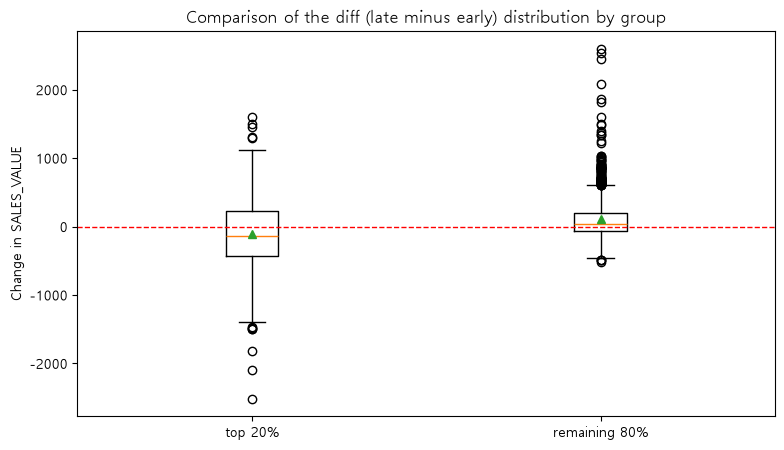

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([top_diff, rest_diff], tick_labels=["top 20%", "remaining 80%"], showmeans=True)
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_title("Comparison of the diff (late minus early) distribution by group")
ax.set_ylabel("Change in SALES_VALUE")
plt.show()


## 9. Next steps

- The third view of H4-1 (the change in the sales share itself) will be handled with a separate bootstrap CI; with the three tests here that makes four tests in total, so the Bonferroni denominator (N_TESTS) must be updated to 4
- H4-2 (new/reactivated cross-analysis) continues once the H1 labeling is settled
- When writing the conclusion (step 6), H4-1 must be described as a "convergence pattern", not in the original direction

## 10. Test D: the change in the sales share itself (bootstrap, third view of H4-1)

So far (tests A/B/C) we looked at "how much the amounts rose and fell"; this time we look at "**did the share (%) of total sales taken by the top 20% itself grow**".
The share is a single value per time point, not a household-level value, so Wilcoxon/Mann-Whitney cannot be used, and the confidence interval is computed directly by bootstrap.

**Note**: the group (top 20% / remaining) labels are already fixed from the early-window spending in the original data and are not recomputed during resampling, to avoid circular reasoning.

In [12]:
def compute_share(df_subset):
    """Compute the sales share (early, late) of the top 20% group from the panel (household x early/late/group)"""
    total_early = df_subset["sales_early"].sum()
    total_late  = df_subset["sales_late"].sum()
    top_early = df_subset.loc[df_subset["group"] == "top 20%", "sales_early"].sum()
    top_late  = df_subset.loc[df_subset["group"] == "top 20%", "sales_late"].sum()

    share_early = top_early / total_early
    share_late  = top_late / total_late
    return share_early, share_late

# Actual share in the original data
obs_share_early, obs_share_late = compute_share(panel)
obs_share_diff = obs_share_late - obs_share_early

print(f"Early-window sales share of the top 20%: {obs_share_early*100:.2f}%")
print(f"Late-window sales share of the top 20%: {obs_share_late*100:.2f}%")
print(f"Change in share (late minus early): {obs_share_diff*100:+.2f} pp")


Early-window sales share of the top 20%: 54.87%
Late-window sales share of the top 20%: 41.96%
Change in share (late minus early): -12.91 pp


In [13]:
# Bootstrap: resample households with replacement (the group labels stay fixed)
n_households = len(panel)
boot_share_diffs = np.empty(N_BOOT)
rng_D = np.random.default_rng(SEED)

panel_reset = panel.reset_index()  # household_key as a column (for convenient sampling)

for i in range(N_BOOT):
    boot_idx = rng_D.choice(panel_reset.index, size=n_households, replace=True)
    boot_sample = panel_reset.loc[boot_idx]
    s_early, s_late = compute_share(boot_sample)
    boot_share_diffs[i] = s_late - s_early

ci_share = np.percentile(boot_share_diffs, [2.5, 97.5])

print(f"Bootstrap repetitions: {N_BOOT}")
print(f"Observed change in share: {obs_share_diff*100:+.2f} pp")
print(f"95% bootstrap CI: ({ci_share[0]*100:+.2f} pp, {ci_share[1]*100:+.2f} pp)")

zero_in_ci = ci_share[0] <= 0 <= ci_share[1]
print(f"\nDoes the CI include 0: {zero_in_ci}")
if zero_in_ci:
    print("-> The change in share is hard to call statistically meaningful")
else:
    direction = "decreased" if obs_share_diff < 0 else "increased"
    print(f"-> The share {direction} significantly (the confidence interval does not include 0)")


Bootstrap repetitions: 5000
Observed change in share: -12.91 pp
95% bootstrap CI: (-14.81 pp, -11.07 pp)

Does the CI include 0: False
-> The share decreased significantly (the confidence interval does not include 0)


In [14]:
# --- source CSVs: revenue share of the initial top 20% and its bootstrap CI
pd.DataFrame([{
    "n_panel": n_households, "n_top": int((panel["group"] == "top 20%").sum()),
    "share_early_pct": obs_share_early * 100, "share_late_pct": obs_share_late * 100,
    "share_diff_pp": obs_share_diff * 100, "ci_low_pp": ci_share[0] * 100, "ci_high_pp": ci_share[1] * 100,
    "n_boot": N_BOOT, "seed": SEED, "ci_includes_zero": bool(zero_in_ci),
}]).to_csv(OUT_DIR / "h4_share_bootstrap.csv", index=False)
pd.DataFrame({"draw": np.arange(N_BOOT), "share_diff_pp": boot_share_diffs * 100}) \
    .to_csv(OUT_DIR / "h4_share_bootstrap_draws.csv", index=False)

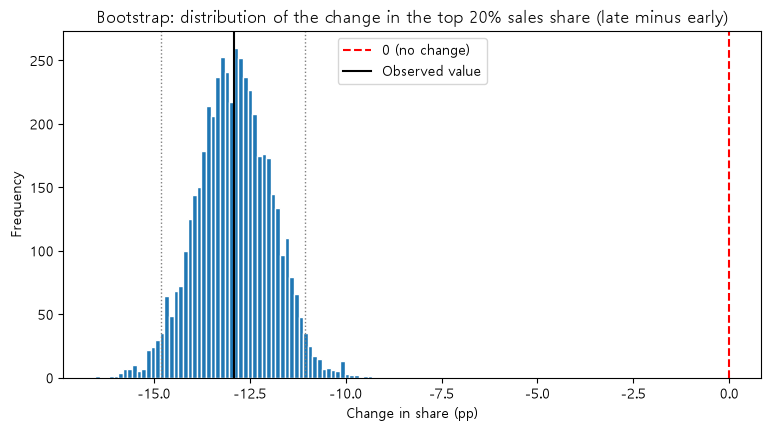

In [15]:
# Plot the bootstrap distribution
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot_share_diffs * 100, bins=60, edgecolor='white')
ax.axvline(0, color='red', linestyle='--', linewidth=1.5, label='0 (no change)')
ax.axvline(obs_share_diff * 100, color='black', linestyle='-', linewidth=1.5, label='Observed value')
ax.axvline(ci_share[0]*100, color='gray', linestyle=':', linewidth=1)
ax.axvline(ci_share[1]*100, color='gray', linestyle=':', linewidth=1)
ax.set_title("Bootstrap: distribution of the change in the top 20% sales share (late minus early)")
ax.set_xlabel("Change in share (pp)")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()


## 11. Final summary for H4-1 (tests A to D)

Update the Bonferroni denominator from 3 to 4 and build the final results table including test D.

**Note on test D**: D has no p-value. It is judged by an unadjusted 95% percentile bootstrap CI (whether the interval excludes 0), which is not a Bonferroni-adjusted criterion. D was planned as the third H4-1 view, but it was added to the multiple-testing family (denominator 3 to 4) only after the results of A-C had been seen.

In [16]:
N_TESTS_FINAL = 4
ALPHA_ADJ_FINAL = 0.05 / N_TESTS_FINAL
print(f"Updated Bonferroni-corrected significance level: {ALPHA_ADJ_FINAL:.4f} (0.05 / {N_TESTS_FINAL} tests)")

# Reuse the p-values of tests A, B, C and re-judge them under the new threshold
for name, p in [("A (top 20%, absolute change)", p_A), ("B (remaining 80%, absolute change)", p_B), ("C (difference between groups)", p_C)]:
    sig = "significant" if p < ALPHA_ADJ_FINAL else "not significant"
    print(f"{name}: p={p:.6f} -> {sig}")

# Test D has no p-value. It is judged by whether its unadjusted 95% percentile bootstrap CI excludes 0,
# which is NOT a Bonferroni-adjusted criterion (the CI is not equivalent to alpha_adj = 0.0125).
# D was planned as the third H4-1 view but was added to the family only after the A-C results were seen.
print(f"D (change in share): CI=({ci_share[0]*100:+.2f} pp, {ci_share[1]*100:+.2f} pp) -> "
      f"{'unadjusted 95% CI includes 0' if zero_in_ci else 'unadjusted 95% CI excludes 0'} "
      "(no p-value; no adjusted interval computed)")

Updated Bonferroni-corrected significance level: 0.0125 (0.05 / 4 tests)
A (top 20%, absolute change): p=0.000020 -> significant
B (remaining 80%, absolute change): p=0.000000 -> significant
C (difference between groups): p=0.000000 -> significant
D (change in share): CI=(-14.81 pp, -11.07 pp) -> unadjusted 95% CI excludes 0 (no p-value; no adjusted interval computed)


In [17]:
# --- source CSV: Bonferroni re-judgement with four tests
pd.DataFrame([
    {"test": "A", "p_value": p_A, "alpha_adj": ALPHA_ADJ_FINAL, "significant": bool(p_A < ALPHA_ADJ_FINAL),
     "decision_basis": "Bonferroni: p < alpha_adj"},
    {"test": "B", "p_value": p_B, "alpha_adj": ALPHA_ADJ_FINAL, "significant": bool(p_B < ALPHA_ADJ_FINAL),
     "decision_basis": "Bonferroni: p < alpha_adj"},
    {"test": "C", "p_value": p_C, "alpha_adj": ALPHA_ADJ_FINAL, "significant": bool(p_C < ALPHA_ADJ_FINAL),
     "decision_basis": "Bonferroni: p < alpha_adj"},
    # D: no p-value; 'significant' here only means the unadjusted 95% bootstrap CI excludes 0 (see decision_basis)
    {"test": "D", "p_value": np.nan, "alpha_adj": ALPHA_ADJ_FINAL, "significant": not zero_in_ci,
     "decision_basis": "Unadjusted 95% bootstrap CI excludes 0 (no p-value)"},
]).to_csv(OUT_DIR / "h4_tests_bonferroni4.csv", index=False)

## 12. H4-1 conclusion

- In amounts (A, B, C): the top 20% fell significantly, the remaining 80% rose significantly, and the difference between groups is significant too -> **convergence pattern**. All three are significant at both the original Bonferroni level for three tests (0.05/3 = about 0.0167) and the updated level for four tests (0.05/4 = 0.0125)
- In share (D): the share of the top 20% fell from 54.87% to 41.96% (-12.91 pp), and the unadjusted 95% percentile bootstrap CI (-14.81 pp, -11.07 pp) excludes 0. D has no p-value and no Bonferroni-adjusted interval was computed, so this is **not** a Bonferroni-adjusted result. D was planned as the third H4-1 view, but it was added to the multiple-testing family (denominator 3 to 4) only after the A-C results had been seen; read it as a post-hoc-added, unadjusted interval result. In `outputs/h4_tests_bonferroni4.csv`, the `significant` value of D only means "the unadjusted CI excludes 0" (see the `decision_basis` column)
- If the two views (amount vs share) agree in direction, H4-1 is clearly rejected; if they differ, describe it as the compromise conclusion "the amounts fell but the share is maintained"
